# Monte Carlo Pricing Lab: GBM, Heston, Jumps + Variance Reduction

Monte Carlo is the engine behind exposure numbers and behind any product without a closed formula. Its results are only useful if they are precise enough, free of discretisation bias, and robust to the choice of model. This notebook calibrates three models to the same option market and measures all three properties.

**What it does.** It calibrates three models (Black–Scholes GBM, Heston stochastic volatility and Merton jump-diffusion) to today's SPY option smile, then prices European, Asian, barrier and digital options by Monte Carlo.

It measures how much each variance-reduction technique buys, how discretisation biases Heston, and how far exotic prices diverge between models that fit the same vanillas.

**Data.** An SPY option chain snapshot and spot (Yahoo Finance), Treasury yields for discounting (FRED), and dividends implied from put–call parity.

**Methods.** COS-method Heston and series Merton pricers for calibration, exact GBM and Merton simulation, and Heston Euler full-truncation and Andersen QE schemes.

The variance-reduction toolkit covers antithetic variates, control variates (geometric Asian, European), scrambled Sobol quasi-Monte Carlo with a Brownian bridge, and importance sampling, plus the Broadie–Glasserman–Kou correction for discrete barriers.

**Key output.** Convergence and efficiency of each technique against closed-form answers, Heston bias by time step, and a model-risk table for exotic prices.

## 1. Why a pricing lab belongs in a risk toolkit

Monte Carlo is the engine behind exposure numbers such as PFE and CVA, and behind any product without a closed form. Two questions decide whether its numbers can be trusted:

1. **Precision:** how many paths are needed for a given standard error? Variance reduction can cut that number by orders of magnitude, which is what makes nested or real-time calculations feasible.
2. **Bias:** does the discretised model price what the continuous model prices? Stochastic volatility is the classic trap: naive Euler schemes are biased in the variance process.

A third question matters for model validation:

3. **Model risk:** if two models fit the vanilla smile equally well, how different are their exotic prices? The spread is a natural measure of the model-risk reserve. GBM, with its single flat volatility, is the benchmark that ignores the smile.

**Models** (risk-neutral, dividend yield $q$):

| Model | Dynamics |
|---|---|
| GBM | $dS/S=(r-q)\,dt+\sigma\,dW$ |
| Heston | $dS/S=(r-q)\,dt+\sqrt v\,dW_1,\quad dv=\kappa(\theta-v)\,dt+\xi\sqrt v\,dW_2,\quad d\langle W_1,W_2\rangle=\rho\,dt$ |
| Merton | $dS/S=(r-q-\lambda\bar k)\,dt+\sigma\,dW+(J-1)\,dN,\quad \ln J\sim N(\mu_J,\delta^2),\ N\sim\text{Poisson}(\lambda)$ |

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")


# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import yfinance as yf
from scipy import stats
from scipy.optimize import brentq, least_squares
from scipy.stats import qmc
import math

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

UNDERLYING = "SPY"
# calibration expiries (closest available)
CAL_DAYS = [30, 60, 91, 182, 273, 365]
K_BAND = (0.80, 1.15)  # strikes as a fraction of spot
SEED = 11
T_EXOTIC = 1.0  # one-year exotics
N_MONITOR = 12  # monthly averaging for the Asian
# down-and-out barrier at 80% of spot, daily monitoring
BARRIER = 0.80
# deep OTM digital call strike (fraction of spot)
DIGITAL_K = 1.30

print(f"yfinance {yf.__version__} · run on {dt.date.today():%Y-%m-%d}")

yfinance 1.7.0 · run on 2026-10-19


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"


MODEL_COLORS = {"GBM": PALETTE[0], "Heston": PALETTE[1], "Merton": PALETTE[2]}

## 3. Data: SPY smile, rates and implied dividends

For each expiry the forward comes from put–call parity on near-the-money strikes, which gives the implied dividend yield $q(T)=r(T)-\ln(F/S)/T$. Implied volatilities come from out-of-the-money mids.

In [3]:
def fetch_chain():
    tk = yf.Ticker(UNDERLYING)
    spot = float(tk.history(period="5d")["Close"].iloc[-1])
    now = pd.Timestamp.now(tz="America/New_York").tz_localize(None)
    exps = pd.to_datetime(pd.Series(tk.options))
    days = (exps - now.normalize()).dt.days
    chosen = sorted({exps[(days - d).abs().idxmin()] for d in CAL_DAYS})
    frames = []
    for e in chosen:
        ch = tk.option_chain(e.strftime("%Y-%m-%d"))
        for kind, df in (("call", ch.calls), ("put", ch.puts)):
            frames.append(df.assign(type=kind, expiry=e))
    chain = pd.concat(frames, ignore_index=True)
    chain["spot"], chain["snapshot"] = spot, now
    return chain.drop(columns=["lastTradeDate"], errors="ignore")


chain = cached("yahoo_spy_chain_mc", fetch_chain, max_age_hours=24)
S0, SNAP = chain["spot"].iloc[0], pd.Timestamp(chain["snapshot"].iloc[0])
FRED_T = {
    "DGS1MO": 1 / 12,
    "DGS3MO": 0.25,
    "DGS6MO": 0.5,
    "DGS1": 1,
    "DGS2": 2,
}
fred_last = {
    t: fred.get_series(s).dropna().iloc[-1] for s, t in FRED_T.items()
}
rate_t, rate_v = np.array(list(fred_last)), np.log(
    1 + np.array(list(fred_last.values())) / 100
)
r_of = lambda T: np.interp(T, rate_t, rate_v)

chain["T"] = (
    pd.to_datetime(chain["expiry"]) + pd.Timedelta(hours=16) - SNAP
).dt.total_seconds() / (365.25 * 86400)
chain["mid"] = (chain["bid"] + chain["ask"]) / 2
chain = chain[
    (chain["bid"] > 0)
    & (chain["ask"] > chain["bid"])
    & ((chain["ask"] - chain["bid"]) / chain["mid"] < 0.25)
]
q_of_T = {}
for e, g in chain.groupby("expiry"):
    piv = g.pivot_table(index="strike", columns="type", values="mid").dropna()
    piv = piv.iloc[(piv.index.to_series() - S0).abs().argsort()[:6]]
    T = g["T"].iloc[0]
    F = np.median(piv.index + np.exp(r_of(T) * T) * (piv["call"] - piv["put"]))
    q_of_T[e] = r_of(T) - np.log(F / S0) / T
chain["r"], chain["q"] = r_of(chain["T"]), chain["expiry"].map(q_of_T)


def bs(S, K, T, sig, r, q, kind="call"):
    sqT = np.sqrt(T)
    d1 = (np.log(S / K) + (r - q + 0.5 * sig**2) * T) / (sig * sqT)
    d2 = d1 - sig * sqT
    call = S * np.exp(-q * T) * stats.norm.cdf(d1) - K * np.exp(
        -r * T
    ) * stats.norm.cdf(d2)
    return np.where(
        np.asarray(kind) == "call",
        call,
        call - S * np.exp(-q * T) + K * np.exp(-r * T),
    )


def bs_vega(S, K, T, sig, r, q):
    d1 = (np.log(S / K) + (r - q + 0.5 * sig**2) * T) / (sig * np.sqrt(T))
    return S * np.exp(-q * T) * stats.norm.pdf(d1) * np.sqrt(T)


def implied_vol(price, K, T, r, q, kind):
    try:
        return brentq(lambda s: bs(S0, K, T, s, r, q, kind) - price, 1e-4, 4.0)
    except ValueError:
        return np.nan


otm = ((chain["type"] == "put") & (chain["strike"] < S0)) | (
    (chain["type"] == "call") & (chain["strike"] >= S0)
)
cal = chain[
    otm & chain["strike"].between(K_BAND[0] * S0, K_BAND[1] * S0)
].copy()
cal["iv"] = [
    implied_vol(p, k, t, r, q, ty)
    for p, k, t, r, q, ty in zip(
        cal["mid"], cal["strike"], cal["T"], cal["r"], cal["q"], cal["type"]
    )
]
cal = cal.dropna(subset=["iv"]).reset_index(drop=True)
cal["vega"] = bs_vega(
    S0, cal["strike"], cal["T"], cal["iv"], cal["r"], cal["q"]
)
R1, Q1 = float(r_of(1.0)), float(
    np.interp(
        1.0,
        [t for t in cal.groupby("expiry")["T"].first()],
        [q_of_T[e] for e in cal.groupby("expiry")["T"].first().index],
    )
)
print(
    f"Snapshot {SNAP:%Y-%m-%d %H:%M} ET · SPY {S0:.2f} ·"
    f" {cal['expiry'].nunique()} expiries · {len(cal)} OTM quotes · r(1y)"
    f" {R1:.2%} · implied q(1y) {Q1:.2%}"
)

Snapshot 2026-10-19 14:47 ET · SPY 767.74 · 6 expiries · 673 OTM quotes · r(1y) 4.39% · implied q(1y) 0.77%


## 4. Calibrating the three models to the same smile

- **GBM:** one volatility, the 1-year at-the-money implied vol.
- **Heston:** COS method (Fang & Oosterlee), five parameters.
- **Merton:** the series formula (a Poisson-weighted sum of Black–Scholes prices), four parameters.

Errors are price differences divided by vega, a fast proxy for implied-volatility errors.

Heston: v0 0.023, kappa 9.233, theta 0.042, xi 2.118, rho -0.705 (Feller 2κθ/ξ² = 0.17)
Merton: sig 0.092, lam 0.546, muJ -0.180, dJ 0.167 · GBM σ = 0.181


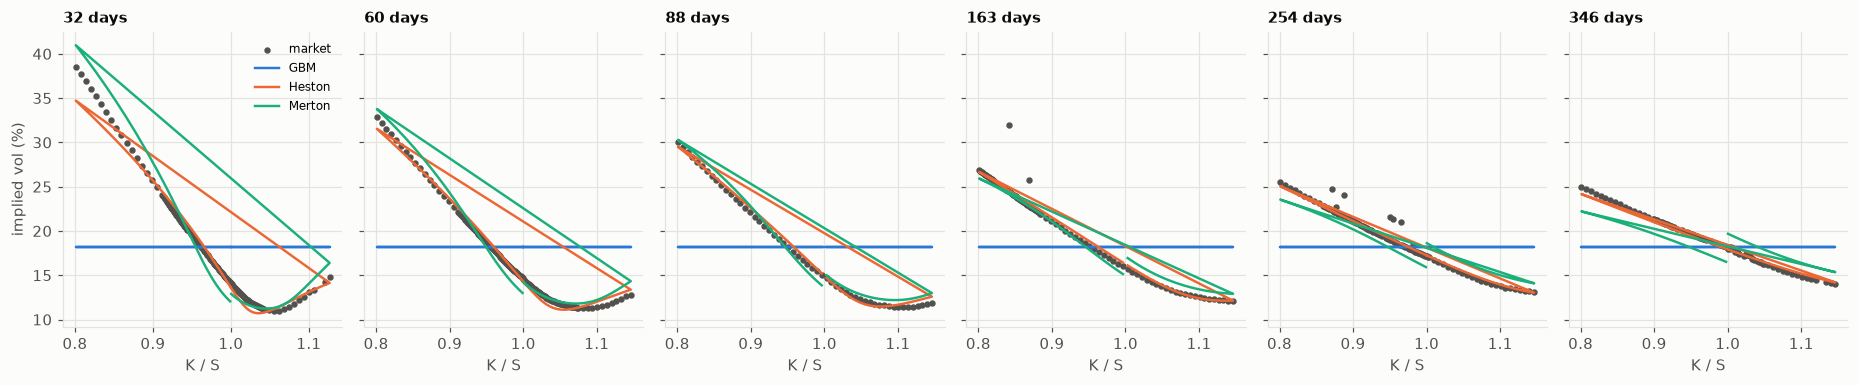

,IV RMSE (vol pts)
GBM,5.09
Heston,0.64
Merton,1.26


In [4]:
def heston_cf(u, T, r, q, v0, kappa, theta, xi, rho):
    iu = 1j * u
    a = kappa - rho * xi * iu
    d = np.sqrt(a**2 + xi**2 * (iu + u**2))
    g = (a - d) / (a + d)
    e = np.exp(-d * T)
    C = (
        kappa
        * theta
        / xi**2
        * ((a - d) * T - 2 * np.log((1 - g * e) / (1 - g)))
    )
    D = (a - d) / xi**2 * (1 - e) / (1 - g * e)
    return np.exp(iu * (r - q) * T + C + D * v0)


def heston_cos(S, K, T, r, q, v0, kappa, theta, xi, rho, kind, N=256, L=12):
    S, K, T, r, q = (
        np.atleast_1d(np.asarray(v, float))[:, None] for v in (S, K, T, r, q)
    )
    S = np.broadcast_to(S, K.shape)
    x = np.log(S / K)
    w = np.maximum(
        theta * T + (v0 - theta) * (1 - np.exp(-kappa * T)) / kappa, 1e-6
    )
    c1 = (r - q) * T - 0.5 * w
    a, b = x + c1 - L * np.sqrt(w), x + c1 + L * np.sqrt(w)
    k = np.arange(N)[None, :]
    u = k * np.pi / (b - a)
    chi = (np.cos(u * (0 - a)) - np.exp(a) + u * np.sin(u * (0 - a))) / (
        1 + u**2
    )
    psi = np.where(k == 0, -a, np.sin(u * (0 - a)) / np.where(k == 0, 1, u))
    U = 2 / (b - a) * (psi - chi)
    cf = heston_cf(u, T, r, q, v0, kappa, theta, xi, rho) * np.exp(
        1j * u * (x - a)
    )
    terms = np.real(cf) * U
    terms[:, 0] *= 0.5
    put = K[:, 0] * np.exp(-r[:, 0] * T[:, 0]) * terms.sum(axis=1)
    call = (
        put
        + S[:, 0] * np.exp(-q[:, 0] * T[:, 0])
        - K[:, 0] * np.exp(-r[:, 0] * T[:, 0])
    )
    return np.where(np.asarray(kind) == "call", call, put)


def merton_price(S, K, T, r, q, sig, lam, muJ, dJ, kind, n_terms=40):
    kbar = np.exp(muJ + 0.5 * dJ**2) - 1
    lam_p = lam * (1 + kbar)
    out = 0.0
    for n in range(n_terms):
        w = np.exp(-lam_p * T) * (lam_p * T) ** n / math.factorial(n)
        sig_n = np.sqrt(sig**2 + n * dJ**2 / T)
        r_n = r - lam * kbar + n * np.log(1 + kbar) / T
        out = out + w * bs(S, K, T, sig_n, r_n, q, kind) * np.exp(
            (r_n - r) * T
        )
    return out


Kc, Tc, rc, qc, tyc, mid, vega = (
    cal[c].to_numpy() for c in ["strike", "T", "r", "q", "type", "mid", "vega"]
)
w_exp = 1 / np.sqrt(
    cal.groupby("expiry")["strike"].transform("size").to_numpy()
)

h_fit = least_squares(
    lambda p: (heston_cos(S0, Kc, Tc, rc, qc, *p, kind=tyc) - mid)
    / np.maximum(vega, 0.5)
    * w_exp,
    x0=[0.02, 2.0, 0.04, 0.8, -0.7],
    bounds=([1e-3, 0.05, 1e-3, 0.05, -0.999], [0.5, 15, 0.5, 3, 0.3]),
)
HESTON = dict(zip(["v0", "kappa", "theta", "xi", "rho"], h_fit.x))
m_fit = least_squares(
    lambda p: (merton_price(S0, Kc, Tc, rc, qc, *p, kind=tyc) - mid)
    / np.maximum(vega, 0.5)
    * w_exp,
    x0=[0.12, 0.5, -0.15, 0.15],
    bounds=([0.01, 0.0, -1.0, 0.01], [1.0, 10.0, 0.5, 1.0]),
)
MERTON = dict(zip(["sig", "lam", "muJ", "dJ"], m_fit.x))
atm_1y = cal.iloc[
    ((cal["T"] - 1.0).abs() + (cal["strike"] / S0 - 1).abs()).argsort()[:3]
]["iv"].mean()
GBM = {"sigma": atm_1y}

cal["iv_heston"] = [
    implied_vol(p, k, t, r, q, ty)
    for p, k, t, r, q, ty in zip(
        heston_cos(S0, Kc, Tc, rc, qc, **HESTON, kind=tyc), Kc, Tc, rc, qc, tyc
    )
]
cal["iv_merton"] = [
    implied_vol(p, k, t, r, q, ty)
    for p, k, t, r, q, ty in zip(
        merton_price(S0, Kc, Tc, rc, qc, **MERTON, kind=tyc),
        Kc,
        Tc,
        rc,
        qc,
        tyc,
    )
]
cal["iv_gbm"] = GBM["sigma"]
fit_tbl = pd.DataFrame({
    m: {
        "IV RMSE (vol pts)": (
            np.sqrt(np.nanmean((cal[f"iv_{m.lower()}"] - cal["iv"]) ** 2))
            * 100
        )
    }
    for m in MODEL_COLORS
}).T
print(
    "Heston: "
    + ", ".join(f"{k} {v:.3f}" for k, v in HESTON.items())
    + " (Feller 2κθ/ξ² ="
    f" {2 * HESTON['kappa'] * HESTON['theta'] / HESTON['xi'] ** 2:.2f})"
)
print(
    "Merton: "
    + ", ".join(f"{k} {v:.3f}" for k, v in MERTON.items())
    + f" · GBM σ = {GBM['sigma']:.3f}"
)

fig, axes = plt.subplots(
    1, cal["expiry"].nunique(), figsize=(17, 3.6), sharey=True
)
for ax, (e, g) in zip(axes, cal.groupby("expiry")):
    m = g["strike"] / S0
    ax.scatter(m, g["iv"] * 100, s=10, color=INK_2, label="market")
    for name, color in MODEL_COLORS.items():
        ax.plot(
            m, g[f"iv_{name.lower()}"] * 100, color=color, lw=1.6, label=name
        )
    ax.set_title(f"{g['T'].iloc[0] * 365:.0f} days", fontsize=10)
    ax.set_xlabel("K / S")
axes[0].set_ylabel("implied vol (%)")
axes[0].legend(fontsize=8)
plt.tight_layout()
save_fig(fig, "01_calibrated_smiles")
plt.show()
fit_tbl.round(2)

## 5. The simulation engines

- **GBM and Merton** are simulated exactly on the monitoring grid: log-normal steps, plus a Poisson number of log-normal jumps per step for Merton.
- **Heston** has no exact simple scheme. Two discretisations are compared:
  - **Euler with full truncation** (Lord et al.): the variance can go negative inside the step, and $\max(v,0)$ is used in the drift and diffusion.
  - **Andersen's QE scheme** (2008): the next variance is drawn from a moment-matched quadratic-Gaussian or exponential mixture, and $\ln S$ is integrated with the trapezoid rule on $v$.
- **Normals** come from pseudo-random numbers, or from scrambled Sobol points mapped through $\Phi^{-1}$ with a **Brownian bridge**, so the first Sobol dimensions drive the largest-scale path features.

In [5]:
def brownian_bridge(z):
    """
    Map n × d standard normals to Brownian paths W(1/d), …, W(1) with the
    bridge ordering:
    column 0 sets W(1), the next columns fill midpoints recursively (Glasserman
    2004, §3.1).
    """
    n, d = z.shape
    t = np.arange(1, d + 1) / d
    W = np.zeros((n, d))
    W[:, -1] = np.sqrt(t[-1]) * z[:, 0]
    queue, k = [(-1, d - 1)], 1
    while queue:
        nxt = []
        for lo, hi in queue:
            if hi - lo < 2:
                continue
            m = (lo + hi) // 2
            t_l, w_l = (0.0, 0.0) if lo < 0 else (t[lo], W[:, lo])
            t_m, t_h = t[m], t[hi]
            W[:, m] = (
                w_l
                + (t_m - t_l) / (t_h - t_l) * (W[:, hi] - w_l)
                + np.sqrt((t_m - t_l) * (t_h - t_m) / (t_h - t_l)) * z[:, k]
            )
            k += 1
            nxt += [(lo, m), (m, hi)]
        queue = nxt
    return W


def normals(n, d, method="pseudo", seed=0):
    """
    n × d unit-variance increments: pseudo-random, or scrambled Sobol through a
    Brownian bridge.
    """
    if method == "pseudo":
        return np.random.default_rng(seed).standard_normal((n, d))
    u = qmc.Sobol(d, scramble=True, seed=seed).random(n)
    z = stats.norm.ppf(np.clip(u, 1e-12, 1 - 1e-12))
    W = brownian_bridge(z)
    return np.diff(np.column_stack([np.zeros(n), W]), axis=1) * np.sqrt(d)


def gbm_paths(n, steps, T, sigma, r, q, z=None, seed=0):
    dt = T / steps
    z = normals(n, steps, seed=seed) if z is None else z
    return S0 * np.exp(
        np.cumsum(
            (r - q - 0.5 * sigma**2) * dt + sigma * np.sqrt(dt) * z, axis=1
        )
    )


def merton_paths(n, steps, T, r, q, sig, lam, muJ, dJ, seed=0):
    rng = np.random.default_rng(seed + 99)
    dt = T / steps
    kbar = np.exp(muJ + 0.5 * dJ**2) - 1
    z = normals(n, steps, seed=seed)
    nj = rng.poisson(lam * dt, (n, steps))
    jumps = muJ * nj + dJ * np.sqrt(nj) * rng.standard_normal((n, steps))
    return S0 * np.exp(
        np.cumsum(
            (r - q - lam * kbar - 0.5 * sig**2) * dt
            + sig * np.sqrt(dt) * z
            + jumps,
            axis=1,
        )
    )


def heston_paths(
    n, steps, T, r, q, v0, kappa, theta, xi, rho, scheme="QE", seed=0
):
    rng = np.random.default_rng(seed)
    dt = T / steps
    lnS, v = np.full(n, np.log(S0)), np.full(n, v0)
    out = np.empty((n, steps))
    e1, e2 = np.exp(-kappa * dt), (1 - np.exp(-kappa * dt))
    for j in range(steps):
        z1, z2 = rng.standard_normal(n), rng.standard_normal(n)
        if scheme == "Euler FT":
            vp = np.maximum(v, 0)
            lnS = lnS + (r - q - 0.5 * vp) * dt + np.sqrt(vp * dt) * z1
            v = (
                v
                + kappa * (theta - vp) * dt
                + xi * np.sqrt(vp * dt) * (rho * z1 + np.sqrt(1 - rho**2) * z2)
            )
        # Andersen QE with γ1 = γ2 = 1/2
        else:
            m = theta + (v - theta) * e1
            s2 = (
                v * xi**2 * e1 / kappa * e2
                + theta * xi**2 / (2 * kappa) * e2**2
            )
            psi = s2 / m**2
            v_new = np.empty(n)
            quad = psi <= 1.5
            b2 = (
                2 / psi[quad]
                - 1
                + np.sqrt(2 / psi[quad]) * np.sqrt(2 / psi[quad] - 1)
            )
            a = m[quad] / (1 + b2)
            v_new[quad] = a * (np.sqrt(b2) + z2[quad]) ** 2
            p = (psi[~quad] - 1) / (psi[~quad] + 1)
            beta = (1 - p) / m[~quad]
            u = stats.norm.cdf(z2[~quad])
            v_new[~quad] = np.where(
                u <= p, 0.0, np.log((1 - p) / np.maximum(1 - u, 1e-300)) / beta
            )
            K0 = -rho * kappa * theta / xi * dt
            K1 = 0.5 * dt * (kappa * rho / xi - 0.5) - rho / xi
            K2 = 0.5 * dt * (kappa * rho / xi - 0.5) + rho / xi
            K3 = K4 = 0.5 * dt * (1 - rho**2)
            lnS = (
                lnS
                + (r - q) * dt
                + K0
                + K1 * v
                + K2 * v_new
                + np.sqrt(K3 * v + K4 * v_new) * z1
            )
            v = v_new
        out[:, j] = np.exp(lnS)
    return out

## 6. Variance reduction under GBM, where exact answers exist

Two benchmarks have closed forms under GBM:

- a **1-year at-the-money European call** (Black–Scholes);
- a **1-year arithmetic Asian call** with monthly averaging. It has no closed form, but its **geometric** twin does (Kemna–Vorst), which makes the geometric Asian an almost perfectly correlated **control variate**. The reference value uses 4 million Sobol paths with the control variate.

Each estimator is run 20 times with independent seeds (for Sobol, independent scramblings). The RMSE against the reference shows its true accuracy, and **efficiency** = 1 / (variance × time) shows how much accuracy each second of compute buys.

In [6]:
sig, r, q, T, K = GBM["sigma"], R1, Q1, T_EXOTIC, S0
disc = np.exp(-r * T)
euro_exact = float(bs(S0, K, T, sig, r, q))

# Geometric Asian (discrete, n fixings at T/n, 2T/n, …, T): log of the
# geometric mean is normal
n = N_MONITOR
t_i = np.arange(1, n + 1) / n * T
mu_g = np.log(S0) + (r - q - 0.5 * sig**2) * t_i.mean()
var_g = sig**2 * np.sum(np.minimum.outer(t_i, t_i)) / n**2
d1 = (mu_g - np.log(K) + var_g) / np.sqrt(var_g)
geo_exact = disc * (
    np.exp(mu_g + 0.5 * var_g) * stats.norm.cdf(d1)
    - K * stats.norm.cdf(d1 - np.sqrt(var_g))
)


def asian_estimators(N, method, seed):
    z = normals(N, n, method, seed)
    out = {}
    for anti in (False, True):
        zz = np.vstack([z, -z]) if anti else z
        S = gbm_paths(len(zz), n, T, sig, r, q, z=zz)
        arith = disc * np.maximum(S.mean(axis=1) - K, 0)
        geo = disc * np.maximum(np.exp(np.log(S).mean(axis=1)) - K, 0)
        euro = disc * np.maximum(S[:, -1] - K, 0)
        b = np.cov(arith, geo)[0, 1] / geo.var()
        tag = " + antithetic" if anti else ""
        out[f"{method}{tag}"] = (arith.mean(), euro.mean())
        out[f"{method}{tag} + control variate"] = (
            (arith - b * (geo - geo_exact)).mean(),
            euro.mean(),
        )
    return out


t0 = time.perf_counter()
ref = np.mean([
    asian_estimators(2**20, "sobol", s)["sobol + control variate"][0]
    for s in range(4)
])
print(
    f"Reference arithmetic Asian {ref:.4f} (geometric {geo_exact:.4f},"
    f" European {euro_exact:.4f}) in {time.perf_counter() - t0:.0f}s"
)

SIZES = [2**k for k in range(10, 18, 1)]
rows = []
for N in SIZES:
    for method in ("pseudo", "sobol"):
        t1 = time.perf_counter()
        runs = [asian_estimators(N, method, s) for s in range(20)]
        elapsed = (time.perf_counter() - t1) / 20
        for name in runs[0]:
            a = np.array([run[name][0] for run in runs])
            e = np.array([run[name][1] for run in runs])
            rows.append({
                "N": N,
                "estimator": name,
                "asian RMSE": np.sqrt(np.mean((a - ref) ** 2)),
                "european RMSE": np.sqrt(np.mean((e - euro_exact) ** 2)),
                "seconds": elapsed / 4,
            })
vr = pd.DataFrame(rows)
vr["efficiency (1 / RMSE² s)"] = 1 / (vr["asian RMSE"] ** 2 * vr["seconds"])
summary = vr[vr["N"] == SIZES[-1]].set_index("estimator")[
    ["asian RMSE", "european RMSE", "seconds"]
]
summary["variance reduction vs plain"] = (
    summary.loc["pseudo", "asian RMSE"] / summary["asian RMSE"]
) ** 2
slopes = vr.groupby("estimator").apply(
    lambda g: np.polyfit(np.log(g["N"]), np.log(g["asian RMSE"]), 1)[0]
)
summary["convergence order"] = slopes
summary[["asian RMSE", "european RMSE"]] *= 100  # in cents
summary = summary.rename(
    columns={
        "asian RMSE": "Asian RMSE (cents)",
        "european RMSE": "European RMSE (cents)",
    }
)
summary.sort_values("Asian RMSE (cents)").style.format({
    "Asian RMSE (cents)": "{:.4f}",
    "European RMSE (cents)": "{:.3f}",
    "seconds": "{:.3f}",
    "variance reduction vs plain": "{:,.0f}",
    "convergence order": "{:.2f}",
})

Reference arithmetic Asian 40.8091 (geometric 39.5180, European 68.7129) in 10s


,Asian RMSE (cents),European RMSE (cents),seconds,variance reduction vs plain,convergence order
estimator,,,,,
sobol + antithetic + control variate,0.0363,0.032,0.054,"130,763",-0.60
sobol + control variate,0.0440,0.044,0.054,"88,955",-0.62
sobol + antithetic,0.1321,0.032,0.054,"9,886",-0.78
sobol,0.1961,0.044,0.054,"4,487",-0.72
pseudo + antithetic + control variate,0.2088,13.776,0.032,"3,957",-0.56
pseudo + control variate,0.3459,19.713,0.032,"1,442",-0.56
pseudo + antithetic,9.4201,13.776,0.032,2,-0.45
pseudo,13.1359,19.713,0.032,1,-0.54


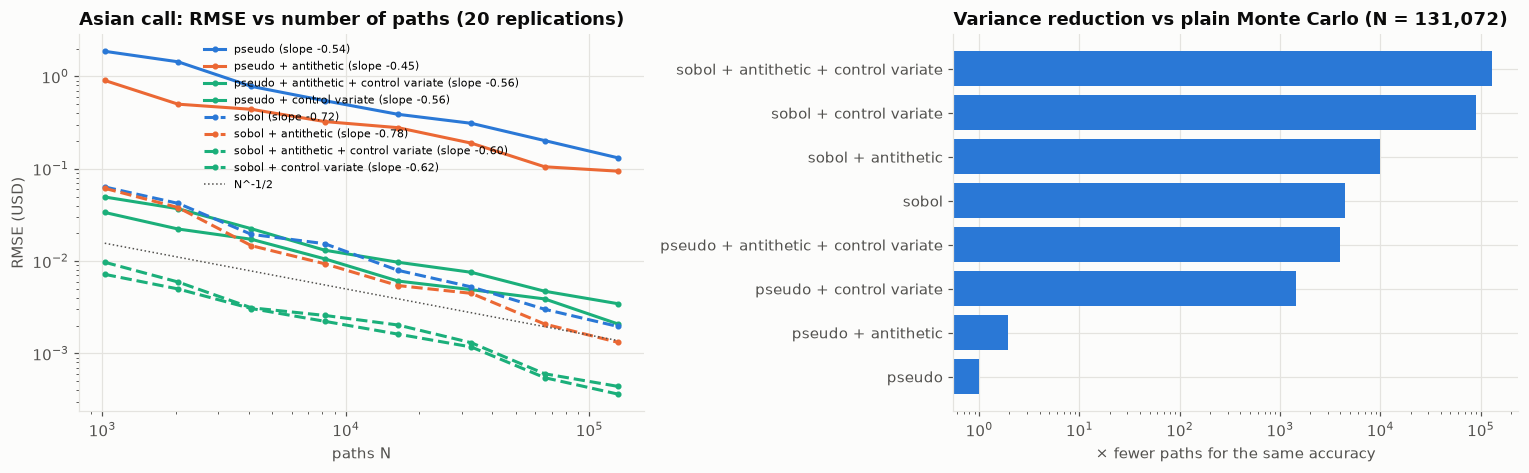

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
ax = axes[0]
styles = {"pseudo": "-", "sobol": "--"}
for name, g in vr.groupby("estimator"):
    base = name.split(" ")[0]
    color = (
        PALETTE[2]
        if "control" in name
        else PALETTE[1] if "antithetic" in name else PALETTE[0]
    )
    ax.loglog(
        g["N"],
        g["asian RMSE"],
        styles[base],
        color=color,
        marker="o",
        ms=3,
        label=f"{name} (slope {slopes[name]:.2f})",
    )
ax.loglog(
    SIZES,
    0.5 * np.array(SIZES, float) ** -0.5,
    ":",
    color=INK_2,
    lw=1,
    label="N^-1/2",
)
ax.set_title("Asian call: RMSE vs number of paths (20 replications)")
ax.set_xlabel("paths N")
ax.set_ylabel("RMSE (USD)")
ax.legend(fontsize=7)
ax = axes[1]
eff = summary["variance reduction vs plain"].sort_values()
ax.barh(eff.index, eff.values, color=PALETTE[0])
ax.set_xscale("log")
ax.set_title(f"Variance reduction vs plain Monte Carlo (N = {SIZES[-1]:,})")
ax.set_xlabel("× fewer paths for the same accuracy")
plt.tight_layout()
save_fig(fig, "02_variance_reduction")
plt.show()

## 7. Heston: discretisation bias of Euler vs QE

The 1-year at-the-money call under the calibrated Heston model has a semi-closed form (COS). Both schemes are run with 200,000 paths at different time steps. The gap to COS is **bias** that more paths cannot remove. Note how the Feller condition matters: when $2\kappa\theta<\xi^2$, as here, the variance often touches zero and Euler's truncation distorts the distribution.

COS price of the 1-year ATM call under calibrated Heston: 68.3529


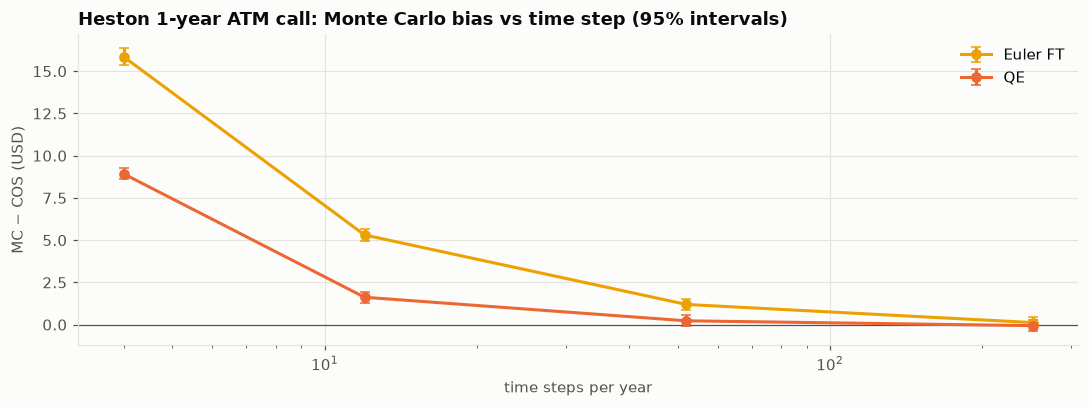

,steps per year,scheme,MC price,std error,bias vs COS,bias / std error,seconds
0,4,Euler FT,84.21,0.25,15.86,62.63,0.04
1,4,QE,77.28,0.16,8.93,55.39,0.07
2,12,Euler FT,73.66,0.19,5.31,27.94,0.10
3,12,QE,69.97,0.16,1.62,9.84,0.22
4,52,Euler FT,69.55,0.17,1.20,7.06,0.56
5,52,QE,68.58,0.17,0.23,1.37,1.41
6,252,Euler FT,68.48,0.17,0.12,0.74,2.88
7,252,QE,68.29,0.16,-0.06,-0.36,7.51


In [8]:
heston_exact = float(
    heston_cos(
        S0,
        np.array([K]),
        np.array([T]),
        np.array([r]),
        np.array([q]),
        **HESTON,
        kind=np.array(["call"]),
    )[0]
)
rows = []
for steps in (4, 12, 52, 252):
    for scheme in ("Euler FT", "QE"):
        t1 = time.perf_counter()
        S = heston_paths(
            200_000, steps, T, r, q, **HESTON, scheme=scheme, seed=steps
        )
        pay = disc * np.maximum(S[:, -1] - K, 0)
        rows.append({
            "steps per year": steps,
            "scheme": scheme,
            "MC price": pay.mean(),
            "std error": pay.std() / np.sqrt(len(pay)),
            "bias vs COS": pay.mean() - heston_exact,
            "bias / std error": (pay.mean() - heston_exact) / (
                pay.std() / np.sqrt(len(pay))
            ),
            "seconds": time.perf_counter() - t1,
        })
bias = pd.DataFrame(rows)
print(
    "COS price of the 1-year ATM call under calibrated Heston:"
    f" {heston_exact:.4f}"
)

fig, ax = plt.subplots(figsize=(10, 3.8))
for scheme, color in [("Euler FT", PALETTE[3]), ("QE", PALETTE[1])]:
    g = bias[bias["scheme"] == scheme]
    ax.errorbar(
        g["steps per year"],
        g["bias vs COS"],
        yerr=1.96 * g["std error"],
        marker="o",
        capsize=3,
        color=color,
        label=scheme,
    )
ax.axhline(0, color=INK_2, lw=0.8)
ax.set_xscale("log")
ax.set_title(
    "Heston 1-year ATM call: Monte Carlo bias vs time step (95% intervals)"
)
ax.set_xlabel("time steps per year")
ax.set_ylabel("MC − COS (USD)")
ax.legend()
plt.tight_layout()
save_fig(fig, "03_heston_discretisation_bias")
plt.show()
bias.round(4)

## 8. Exotics across models: the model-risk table

Heston and Merton are calibrated to the same smile; GBM uses the 1-year ATM volatility. Four 1-year products are priced in each:

- the **European ATM call** (a sanity check: the models should agree),
- the **arithmetic Asian**,
- a **down-and-out call** with an 80% barrier and daily monitoring, using the Broadie–Glasserman–Kou continuity correction to check the GBM simulation against the closed form,
- a **digital call** struck at 130%, priced under GBM with **importance sampling**. The drift is shifted so that half the paths finish in the money, and each payoff is reweighted by the likelihood ratio.

The spread between the two smile-consistent models for the same product is the model risk a validator would reserve against. The GBM column shows the error of ignoring the smile altogether.

In [9]:
N_EX, STEPS = 100_000, 252
H = BARRIER * S0
fix_idx = (np.arange(1, N_MONITOR + 1) * STEPS // N_MONITOR) - 1
paths = {
    "GBM": gbm_paths(N_EX, STEPS, T, sig, r, q, seed=1),
    "Heston": heston_paths(
        N_EX, STEPS, T, r, q, **HESTON, scheme="QE", seed=2
    ),
    "Merton": merton_paths(N_EX, STEPS, T, r, q, **MERTON, seed=3),
}
rows = []
for name, S in paths.items():
    euro = disc * np.maximum(S[:, -1] - K, 0)
    asian = disc * np.maximum(S[:, fix_idx].mean(axis=1) - K, 0)
    dao = disc * np.maximum(S[:, -1] - K, 0) * (S.min(axis=1) > H)
    dig = disc * (S[:, -1] > DIGITAL_K * S0)
    rows.append({
        "model": name,
        "European call": euro.mean(),
        "Asian call": asian.mean(),
        "down-and-out call": dao.mean(),
        "digital 130%": dig.mean(),
        "digital std error": dig.std() / np.sqrt(N_EX),
    })
exotics = pd.DataFrame(rows).set_index("model")


# --- Closed forms under GBM for checks
def dao_call_continuous(S, K, H, T, sig, r, q):
    lam = (r - q + 0.5 * sig**2) / sig**2
    y = np.log(H**2 / (S * K)) / (sig * np.sqrt(T)) + lam * sig * np.sqrt(T)
    c_di = S * np.exp(-q * T) * (H / S) ** (2 * lam) * stats.norm.cdf(
        y
    ) - K * np.exp(-r * T) * (H / S) ** (2 * lam - 2) * stats.norm.cdf(
        y - sig * np.sqrt(T)
    )
    return float(bs(S, K, T, sig, r, q)) - c_di


# BGK: discrete monitoring ≈ continuous with a shifted barrier
H_shift = H * np.exp(-0.5826 * sig * np.sqrt(T / STEPS))
d2_dig = (np.log(S0 / (DIGITAL_K * S0)) + (r - q - 0.5 * sig**2) * T) / (
    sig * np.sqrt(T)
)
checks = pd.Series({
    "European (Black–Scholes)": euro_exact,
    "Asian (reference)": ref,
    "down-and-out (BGK closed form)": dao_call_continuous(
        S0, K, H_shift, T, sig, r, q
    ),
    "digital (closed form)": disc * stats.norm.cdf(d2_dig),
})

# --- Importance sampling for the digital under GBM
z = np.random.default_rng(7).standard_normal(N_EX)
# moves the median to the strike
shift = (np.log(DIGITAL_K) - (r - q - 0.5 * sig**2) * T) / (sig * np.sqrt(T))
ST = S0 * np.exp((r - q - 0.5 * sig**2) * T + sig * np.sqrt(T) * (z + shift))
lr = np.exp(-shift * z - 0.5 * shift**2)
dig_is = disc * (ST > DIGITAL_K * S0) * lr
is_gain = (
    exotics.loc["GBM", "digital std error"] / (dig_is.std() / np.sqrt(N_EX))
) ** 2
print(
    "Digital 130% under GBM: plain MC"
    f" {exotics.loc['GBM', 'digital 130%']:.5f} ±"
    f" {exotics.loc['GBM', 'digital std error']:.5f} · importance sampling"
    f" {dig_is.mean():.5f} ± {dig_is.std() / np.sqrt(N_EX):.5f} (variance"
    f" reduction ×{is_gain:.1f}) · closed form"
    f" {checks['digital (closed form)']:.5f}"
)
display(checks.to_frame("GBM closed form / reference").round(4))

# per USD 100 of digital payout
exotics[["digital 130%", "digital std error"]] *= 100
exotics = exotics.rename(
    columns={
        "digital 130%": "digital 130% (per 100)",
        "digital std error": "digital s.e. (per 100)",
    }
)
prices = exotics.drop(columns="digital s.e. (per 100)")
exotics.loc["Heston vs Merton spread (%)"] = (
    (prices.loc["Heston"] - prices.loc["Merton"]).abs()
    / prices.loc[["Heston", "Merton"]].mean()
    * 100
)
exotics.loc["GBM vs smile models (%)"] = (
    prices.loc["GBM"] / prices.loc[["Heston", "Merton"]].mean() - 1
) * 100
exotics.round(3)

Digital 130% under GBM: plain MC 0.08671 ± 0.00087 · importance sampling 0.08668 ± 0.00036 (variance reduction ×5.8) · closed form 0.08672


,GBM closed form / reference
European (Black–Scholes),68.71
Asian (reference),40.81
down-and-out (BGK closed form),68.44
digital (closed form),0.09


,European call,Asian call,down-and-out call,digital 130% (per 100),digital s.e. (per 100)
model,,,,,
GBM,68.88,40.89,68.63,8.67,0.09
Heston,68.32,38.89,67.02,3.55,0.06
Merton,70.62,40.14,70.57,4.67,0.07
Heston vs Merton spread (%),3.32,3.17,5.15,27.07,NaN
GBM vs smile models (%),-0.85,3.48,-0.24,110.92,NaN


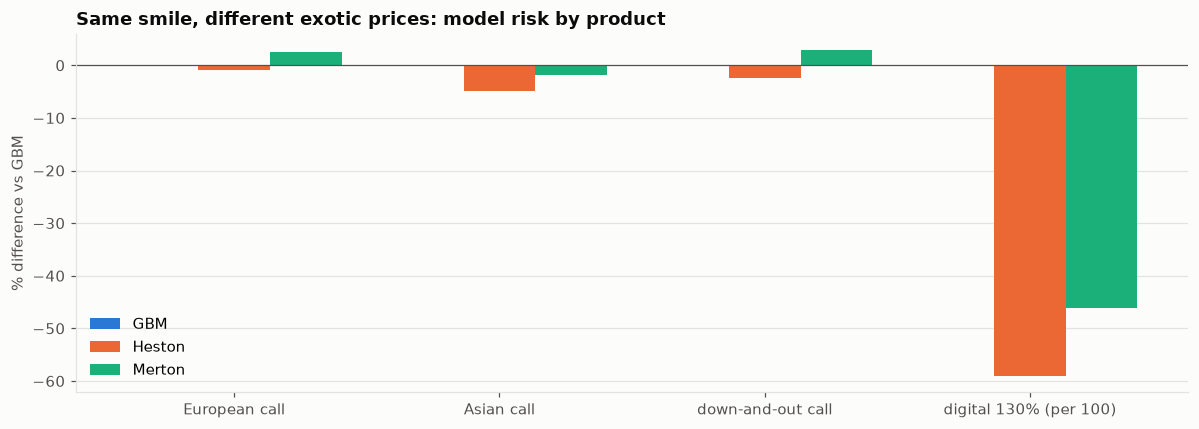

In [10]:
fig, ax = plt.subplots(figsize=(11, 4))
prods = [
    "European call",
    "Asian call",
    "down-and-out call",
    "digital 130% (per 100)",
]
base = exotics.loc[list(MODEL_COLORS), prods]
rel = base / base.loc["GBM"] * 100 - 100
xp = np.arange(len(prods))
for k, (m, color) in enumerate(MODEL_COLORS.items()):
    ax.bar(xp + (k - 1) * 0.27, rel.loc[m], 0.27, color=color, label=m)
ax.axhline(0, color=INK_2, lw=0.8)
ax.set_xticks(xp, prods)
ax.set_ylabel("% difference vs GBM")
ax.set_title("Same smile, different exotic prices: model risk by product")
ax.legend()
ax.grid(axis="x", visible=False)
plt.tight_layout()
save_fig(fig, "04_model_risk_exotics")
plt.show()
vr.to_csv(OUT_DIR / "variance_reduction_study.csv", index=False)
bias.to_csv(OUT_DIR / "heston_discretisation_bias.csv", index=False)
exotics.to_csv(OUT_DIR / "exotic_prices_by_model.csv")
pd.DataFrame(
    {"Heston": pd.Series(HESTON), "Merton": pd.Series(MERTON)}
).to_csv(OUT_DIR / "calibrated_parameters.csv")

## 9. Reading the results and limitations

SPY snapshot of 19 Oct 2026, 1-year products:

- **Calibration.**
  - Heston fits the smile to 0.6 vol points with fast mean reversion and a very high vol of variance (κ ≈ 9, ξ ≈ 2.1, ρ ≈ −0.7). The Feller ratio is 0.17, so the variance hits zero often.
  - Merton fits to 1.3 points with about one jump every two years averaging −18%.
  - Flat GBM misses the smile by 5 points.
- **Variance reduction is the cheapest performance gain in quantitative finance.** At 131k paths, measured against a 4-million-path reference:
  - antithetic variates alone give ×2;
  - the **geometric-Asian control variate** gives ×1,400 (correlation with the arithmetic payoff above 0.999);
  - scrambled **Sobol + Brownian bridge** gives ×4,500;
  - Sobol + control variate gives ×89,000, and adding antithetic variates ×130,000.

In other words, 1 path of the best estimator is worth about 100,000 plain ones. QMC's convergence order is about −0.7 rather than the textbook −1, because the payoff kink reduces the effective smoothness.

**Heston discretisation bias is large and invisible in standard errors.** With monthly steps, Euler full truncation overprices the ATM call by $5.3 (28 standard errors) and QE by $1.6. At weekly steps QE is unbiased within error (0.23, 1.4 s.e.) while Euler is still off by $1.2. With a Feller ratio this low, use QE or a fine grid. More paths do not help.

- **The control checks pass:** the GBM down-and-out matches the Broadie–Glasserman–Kou corrected closed form, and the digital matches its closed form. **Importance sampling** cuts the variance of the 130% digital ×5.8.

**Model risk.** Heston and Merton price the same smile's European call 3.3% apart and the barrier 5% apart, and the deep OTM **digital differs by 27%** (3.55 vs 4.67 per 100). That last number is the model-risk reserve a validator would set. Ignoring the smile (GBM) **doubles** the digital's price, because flat 18% volatility puts far too much probability on a 30% rally when the market's OTM calls trade at much lower implied vol.

**Limitations**

- Single snapshot of the smile; constant rates and dividend yields per expiry.
- Heston and Merton are each calibrated alone. Combining them (Bates) or adding local-volatility corrections would fit the short end better and change the model-risk spread.
- Randomised QMC error bars come from 20 scramblings. Its convergence order depends on payoff smoothness: the kinks of the Asian and barrier payoffs reduce the gain relative to smooth integrands.

## References

### Finance and regulation

- Heston, S. L. (1993). A closed-form solution for options with stochastic volatility with applications to bond and currency options. *The Review of Financial Studies, 6*(2), 327–343. https://doi.org/10.1093/rfs/6.2.327
- Merton, R. C. (1976). Option pricing when underlying stock returns are discontinuous. *Journal of Financial Economics, 3*(1–2), 125–144. https://doi.org/10.1016/0304-405X(76)90022-2
- Andersen, L. (2008). Simple and efficient simulation of the Heston stochastic volatility model. *Journal of Computational Finance, 11*(3), 1–42. https://doi.org/10.21314/JCF.2008.189
- Broadie, M., Glasserman, P., & Kou, S. (1997). A continuity correction for discrete barrier options. *Mathematical Finance, 7*(4), 325–349. https://doi.org/10.1111/1467-9965.00035
- Fang, F., & Oosterlee, C. W. (2009). A novel pricing method for European options based on Fourier-cosine series expansions. *SIAM Journal on Scientific Computing, 31*(2), 826–848. https://doi.org/10.1137/080718061
- Kemna, A. G. Z., & Vorst, A. C. F. (1990). A pricing method for options based on average asset values. *Journal of Banking & Finance, 14*(1), 113–129. https://doi.org/10.1016/0378-4266(90)90039-5

### Machine learning and deep learning

- Glasserman, P. (2004). *Monte Carlo methods in financial engineering*. Springer. https://doi.org/10.1007/978-0-387-21617-1
- Sobol', I. M. (1967). On the distribution of points in a cube and the approximate evaluation of integrals. *USSR Computational Mathematics and Mathematical Physics, 7*(4), 86–112. https://doi.org/10.1016/0041-5553(67)90144-9
- Owen, A. B. (1997). Scrambled net variance for integrals of smooth functions. *The Annals of Statistics, 25*(4), 1541–1562. https://doi.org/10.1214/aos/1031594731